<a href="https://colab.research.google.com/github/samratsingh735594-ctrl/DSV-LAB-2-YEAR/blob/main/DataVisualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
customers = pd.read_csv("customers.csv")
order_items= pd.read_csv("order_items.csv")
orders = pd.read_csv("orders.csv")
products = pd.read_csv("products.csv")
payments = pd.read_csv("payments.csv")


In [4]:
import matplotlib.pyplot as plt


Q1

In [10]:
df_merged = (
    order_items[["order_id", "price"]]
    .merge(orders[["order_id", "customer_id"]], on="order_id")
    .merge(customers[["customer_id", "customer_state"]], on="customer_id")
)
top10_states = (
    df_merged.groupby("customer_state", as_index=False)
    .agg(
        total_item_price=("price", "sum"),
        distinct_orders=("order_id", "nunique"),
    )
    .sort_values("total_item_price", ascending=False)
    .head(10)
)

customer_state  total_item_price  distinct_orders
            SP         5427808.0            16188
            RJ         1669256.0             5079
            MG         1508676.0             4378
            RS          829301.0             2184
            PR          711489.0             1905
            SC          464679.0             1406
            BA          442008.0             1275
            DF          288017.0              844
            GO          276987.0              740
            ES          263805.0              752


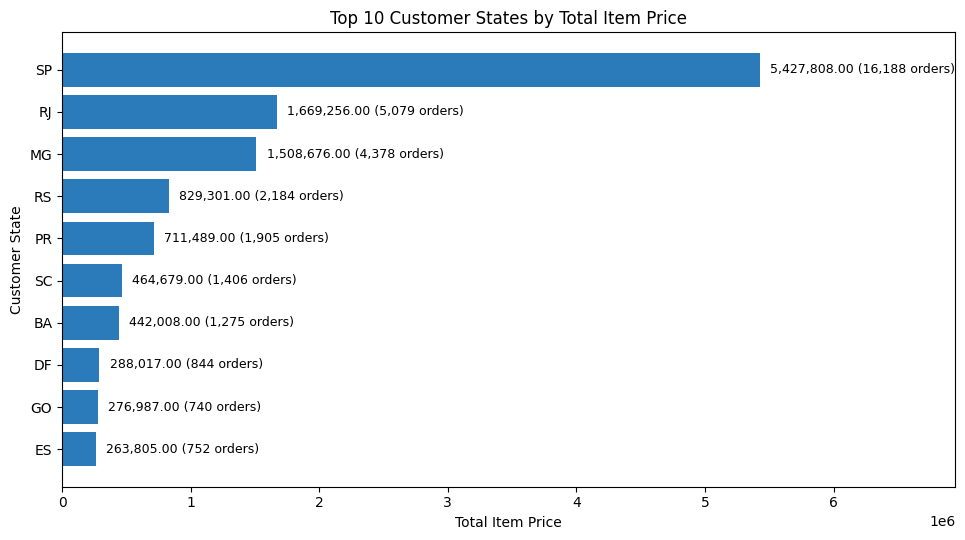

In [12]:
print(top10_states.to_string(index=False))
plot_df = top10_states.iloc[::-1]

plt.figure(figsize=(10, 5.5))
bars = plt.barh(plot_df["customer_state"], plot_df["total_item_price"], color="#2b7bba")

plt.xlabel("Total Item Price")
plt.ylabel("Customer State")
plt.title("Top 10 Customer States by Total Item Price")

max_val = plot_df["total_item_price"].max()
plt.xlim(0, max_val * 1.28)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    plt.text(
        bar.get_width() + max_val * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{row['total_item_price']:,.2f} ({int(row['distinct_orders']):,} orders)",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

Q2

       category  total_item_price
           toys         9795863.0
   garden_tools          413361.0
furniture_decor          340719.0
 bed_bath_table          252201.0
  health_beauty          245294.0
  watches_gifts          243865.0
      telephony          233747.0
 sports_leisure          226183.0


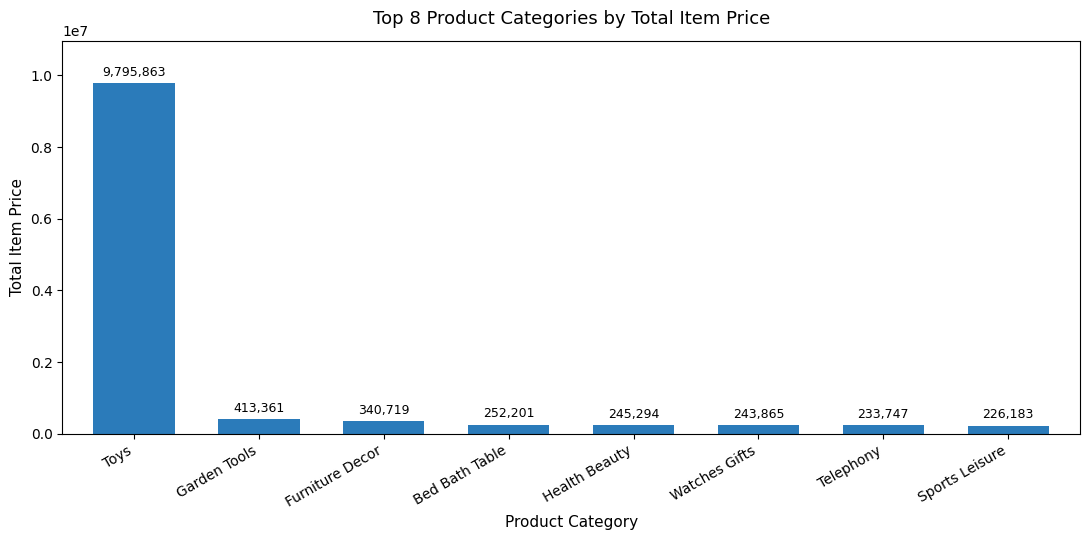

In [13]:
products["category"] = (
    products["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

df_merged = order_items[["product_id", "price"]].merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left",
)
df_merged["category"] = df_merged["category"].fillna("Unknown")

top8_categories = (
    df_merged.groupby("category", as_index=False)["price"]
    .sum()
    .rename(columns={"price": "total_item_price"})
    .sort_values("total_item_price", ascending=False)
    .head(8)
)

top8_categories["display_category"] = (
    top8_categories["category"].str.replace("_", " ").str.title()
)

print(top8_categories[["category", "total_item_price"]].to_string(index=False))

ax = top8_categories.plot(
    kind="bar",
    x="display_category",
    y="total_item_price",
    legend=False,
    figsize=(11, 5.5),
    color="#2b7bba",
    width=0.65,
)

ax.set_title("Top 8 Product Categories by Total Item Price", fontsize=13, pad=12)
ax.set_xlabel("Product Category", fontsize=11)
ax.set_ylabel("Total Item Price", fontsize=11)

plt.xticks(rotation=30, ha="right", fontsize=10)

max_val = top8_categories["total_item_price"].max()
ax.set_ylim(0, max_val * 1.12)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

Q3

Observation period: 2016-10-03 to 2018-09-03
purchase_month  total_payment_value  is_partial
       2016-10              33233.0        True
       2016-12                352.0       False
       2017-01              92384.0       False
       2017-02             167059.0       False
       2017-03             276610.0       False
       2017-04             259751.0       False
       2017-05             373067.0       False
       2017-06             326921.0       False
       2017-07             430721.0       False
       2017-08             494764.0       False
       2017-09             471612.0       False
       2017-10             485367.0       False
       2017-11             835124.0       False
       2017-12             546592.0       False
       2018-01             760917.0       False
       2018-02             749743.0       False
       2018-03             696831.0       False
       2018-04             715733.0       False
       2018-05             710366.0       F

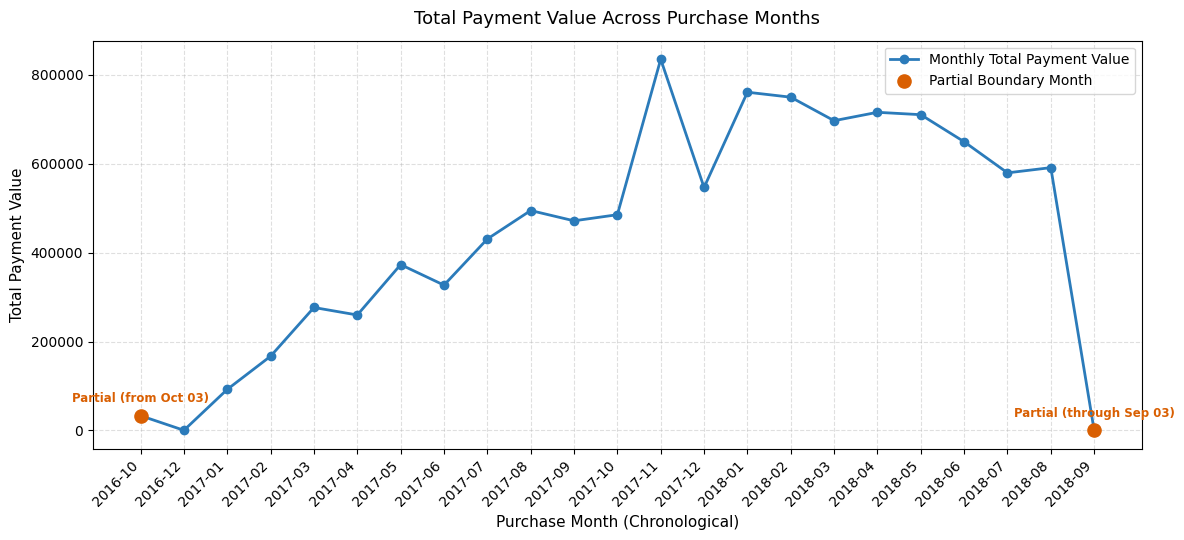

In [17]:
df_merged = payments[["order_id", "payment_value"]].merge(
    orders[["order_id", "order_purchase_timestamp"]].dropna(),
    on="order_id",
)

df_merged["order_purchase_timestamp"] = pd.to_datetime(
    df_merged["order_purchase_timestamp"]
)

min_ts = df_merged["order_purchase_timestamp"].min()
max_ts = df_merged["order_purchase_timestamp"].max()

df_merged["purchase_month"] = df_merged["order_purchase_timestamp"].dt.to_period("M")

monthly_payments = (
    df_merged.groupby("purchase_month", as_index=False)["payment_value"]
    .sum()
    .rename(columns={"payment_value": "total_payment_value"})
    .sort_values("purchase_month")
)

first_month = monthly_payments["purchase_month"].iloc[0]
last_month = monthly_payments["purchase_month"].iloc[-1]

first_is_partial = min_ts.day > 1
last_is_partial = max_ts.day < max_ts.days_in_month

monthly_payments["is_partial"] = False
if first_is_partial:
    monthly_payments.loc[monthly_payments["purchase_month"] == first_month, "is_partial"] = True
if last_is_partial:
    monthly_payments.loc[monthly_payments["purchase_month"] == last_month, "is_partial"] = True

print(f"Observation period: {min_ts.date()} to {max_ts.date()}")
print(monthly_payments.to_string(index=False))

x_labels = monthly_payments["purchase_month"].astype(str)
y_values = monthly_payments["total_payment_value"]

plt.figure(figsize=(12, 5.5))
plt.plot(
    x_labels,
    y_values,
    marker="o",
    linewidth=2,
    markersize=6,
    color="#2b7bba",
    label="Monthly Total Payment Value",
)

partial_rows = monthly_payments[monthly_payments["is_partial"]]
if not partial_rows.empty:
    plt.scatter(
        partial_rows["purchase_month"].astype(str),
        partial_rows["total_payment_value"],
        color="#d95f02",
        s=90,
        zorder=5,
        label="Partial Boundary Month",
    )
    for _, row in partial_rows.iterrows():
        m_str = str(row["purchase_month"])
        note = (
            f"Partial (from {min_ts.strftime('%b %d')})"
            if row["purchase_month"] == first_month
            else f"Partial (through {max_ts.strftime('%b %d')})"
        )
        plt.annotate(
            note,
            (m_str, row["total_payment_value"]),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontsize=8.5,
            color="#d95f02",
            fontweight="bold",
        )

plt.title("Total Payment Value Across Purchase Months", fontsize=13, pad=12)
plt.xlabel("Purchase Month (Chronological)", fontsize=11)
plt.ylabel("Total Payment Value", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

Q4

payment_type    Credit Card  Debit Card  Voucher  Wallet
customer_state                                          
SP                    12021         244      919    3004
RJ                     3824          61      327     867
MG                     3216          50      210     902
RS                     1511          14       92     567
PR                     1382          16       84     423


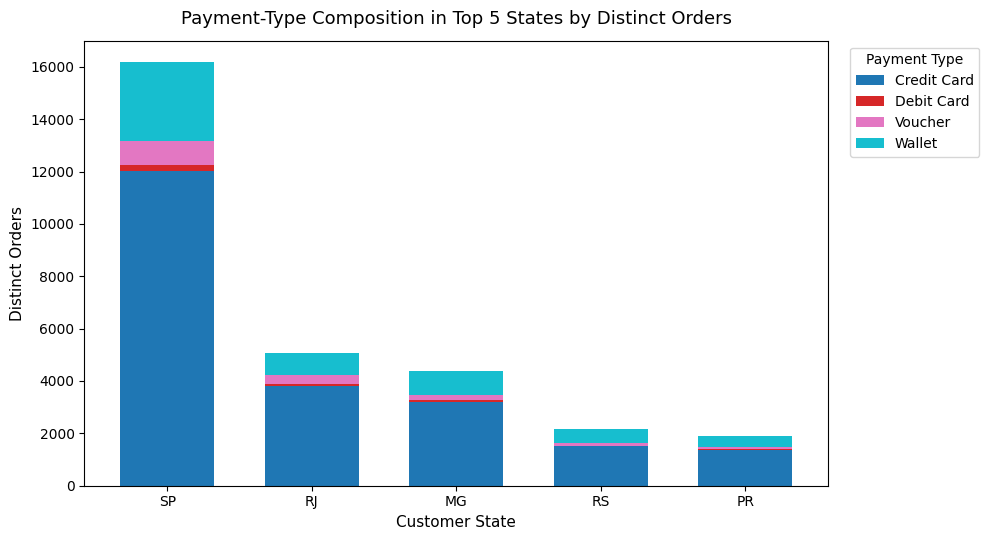

In [18]:
ord_cust = orders[["order_id", "customer_id"]].merge(
    customers[["customer_id", "customer_state"]], on="customer_id"
)

top5_states = (
    ord_cust.groupby("customer_state")["order_id"]
    .nunique()
    .nlargest(5)
    .index.tolist()
)

df_merged = ord_cust[ord_cust["customer_state"].isin(top5_states)].merge(
    payments[["order_id", "payment_type"]], on="order_id"
)
df_merged["payment_type"] = (
    df_merged["payment_type"]
    .fillna("Unknown")
    .str.replace("_", " ")
    .str.title()
)

piv_payment = (
    df_merged.groupby(["customer_state", "payment_type"])["order_id"]
    .nunique()
    .unstack(fill_value=0)
    .loc[top5_states]
)

print(piv_payment)

ax = piv_payment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5.5),
    width=0.65,
    colormap="tab10",
)

ax.set_title("Payment-Type Composition in Top 5 States by Distinct Orders", fontsize=13, pad=12)
ax.set_xlabel("Customer State", fontsize=11)
ax.set_ylabel("Distinct Orders", fontsize=11)
plt.xticks(rotation=0, fontsize=10)
plt.legend(title="Payment Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Q5

             category  distinct_orders  mean_item_price  mean_shipping_charges
                 toys            28697       341.354950              44.696205
        health_beauty             1038       236.314066              41.968208
       bed_bath_table              948       266.034810              42.280591
       sports_leisure              804       281.322139              43.064677
computers_accessories              746       272.540214              41.903485
      furniture_decor              744       457.955645              43.958333
           housewares              586       289.984642              42.943686
        watches_gifts              489       498.701431              42.112474


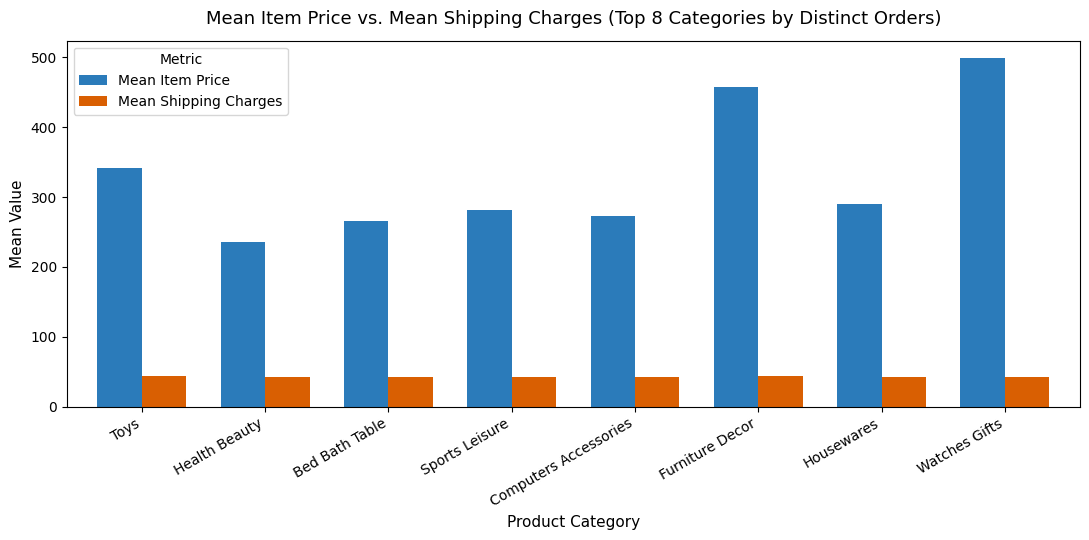

In [20]:
products["category"] = (
    products["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

df_merged = order_items[["order_id", "product_id", "price", "shipping_charges"]].merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left",
)
df_merged["category"] = df_merged["category"].fillna("Unknown")

top8_order_cats = (
    df_merged.groupby("category", as_index=False)
    .agg(
        distinct_orders=("order_id", "nunique"),
        mean_item_price=("price", "mean"),
        mean_shipping_charges=("shipping_charges", "mean"),
    )
    .sort_values("distinct_orders", ascending=False)
    .head(8)
)

top8_order_cats["display_category"] = (
    top8_order_cats["category"].str.replace("_", " ").str.title()
)

print(
    top8_order_cats[
        ["category", "distinct_orders", "mean_item_price", "mean_shipping_charges"]
    ].to_string(index=False)
)

ax = top8_order_cats.set_index("display_category")[
    ["mean_item_price", "mean_shipping_charges"]
].plot(
    kind="bar",
    figsize=(11, 5.5),
    width=0.72,
    color=["#2b7bba", "#d95f02"],
)

ax.set_title(
    "Mean Item Price vs. Mean Shipping Charges (Top 8 Categories by Distinct Orders)",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Product Category", fontsize=11)
ax.set_ylabel("Mean Value", fontsize=11)
ax.legend(["Mean Item Price", "Mean Shipping Charges"], title="Metric")

plt.xticks(rotation=30, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

Q6

customer_state    SP   RJ   MG   RS
purchase_hour                      
0                407  138   83   70
1                202   80   47   21
2                 97   39   16   10
3                 46   20   10    8
4                 44   11    6    7
5                 34   19    5   13
6                 76   19   19    6
7                192   64   57   11
8                471  116  148   54
9                716  237  216  132
10              1053  297  266  112
11              1022  312  298  114
12              1038  332  266  115
13              1107  297  307  135
14              1072  361  312  167
15              1065  334  269  126
16              1075  349  305  147
17              1006  304  282  137
18               921  324  244  102
19               915  325  260  135
20               990  297  264  162
21               944  300  271  137
22               983  269  247  154
23               712  235  180  109


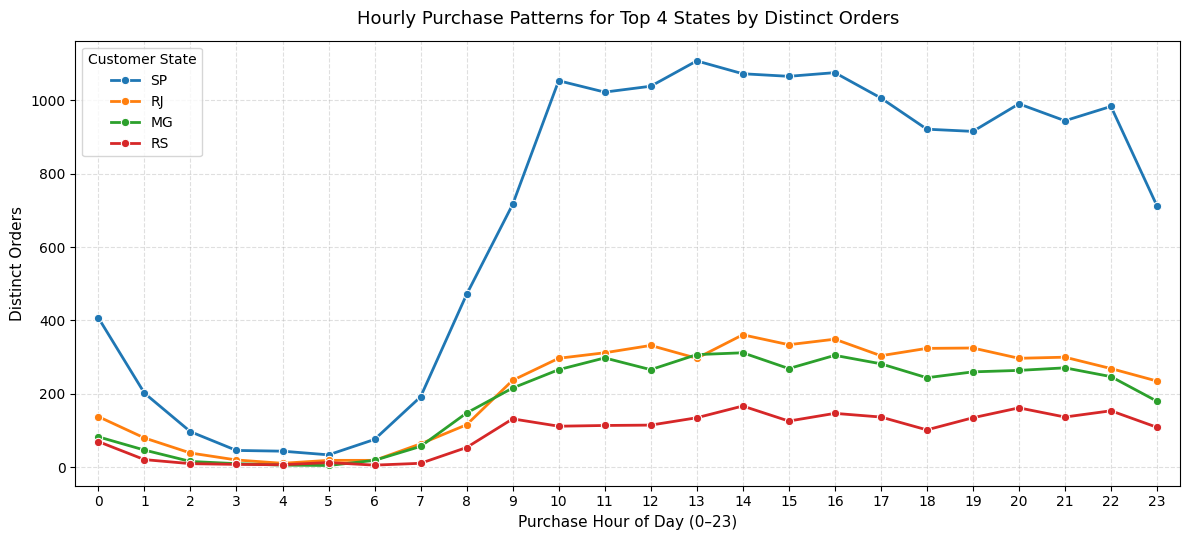

In [21]:
import seaborn as sns

ord_cust = orders.dropna(subset=["order_purchase_timestamp"]).merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
)
ord_cust["order_purchase_timestamp"] = pd.to_datetime(
    ord_cust["order_purchase_timestamp"]
)

top4_states = (
    ord_cust.groupby("customer_state")["order_id"]
    .nunique()
    .nlargest(4)
    .index.tolist()
)

sub = ord_cust[ord_cust["customer_state"].isin(top4_states)].copy()
sub["purchase_hour"] = sub["order_purchase_timestamp"].dt.hour

hourly_counts = (
    sub.groupby(["customer_state", "purchase_hour"], as_index=False)["order_id"]
    .nunique()
    .rename(columns={"order_id": "distinct_orders"})
)

full_grid = pd.MultiIndex.from_product(
    [top4_states, range(24)],
    names=["customer_state", "purchase_hour"],
).to_frame(index=False)

hourly_full = full_grid.merge(
    hourly_counts,
    on=["customer_state", "purchase_hour"],
    how="left",
).fillna({"distinct_orders": 0})

hourly_full["distinct_orders"] = hourly_full["distinct_orders"].astype(int)

print(
    hourly_full.pivot(
        index="purchase_hour",
        columns="customer_state",
        values="distinct_orders",
    )[top4_states]
)

plt.figure(figsize=(12, 5.5))
sns.lineplot(
    data=hourly_full,
    x="purchase_hour",
    y="distinct_orders",
    hue="customer_state",
    hue_order=top4_states,
    marker="o",
    linewidth=2,
)

plt.xticks(range(0, 24))
plt.xlim(-0.5, 23.5)
plt.xlabel("Purchase Hour of Day (0–23)", fontsize=11)
plt.ylabel("Distinct Orders", fontsize=11)
plt.title("Hourly Purchase Patterns for Top 4 States by Distinct Orders", fontsize=13, pad=12)
plt.legend(title="Customer State")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q7

Distinct customers with items: 38,279
Max orders per customer_id: 1
count    38279.000000
mean       342.533295
std        560.289323
min          1.000000
25%         60.000000
50%        137.000000
75%        399.000000
90%        820.000000
95%       1186.300000
99%       2899.000000
max       6729.000000
Name: total_item_price, dtype: float64


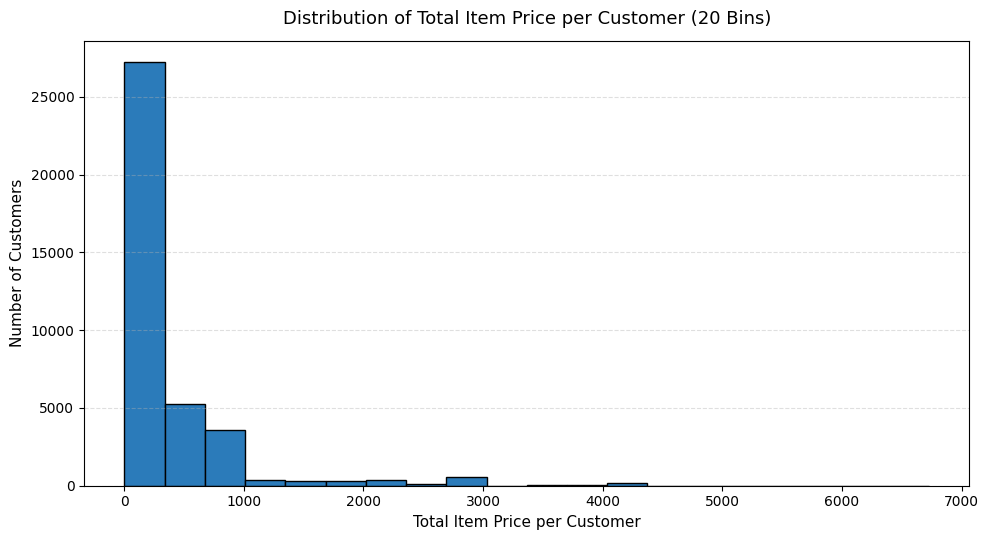

In [22]:
cust_totals = (
    orders[["order_id", "customer_id"]]
    .merge(order_items[["order_id", "price"]], on="order_id")
    .groupby("customer_id", as_index=False)["price"]
    .sum()
    .rename(columns={"price": "total_item_price"})
)

orders_per_cust = orders.groupby("customer_id")["order_id"].nunique()
print(f"Distinct customers with items: {len(cust_totals):,}")
print(f"Max orders per customer_id: {orders_per_cust.max()}")
print(
    cust_totals["total_item_price"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

plt.figure(figsize=(10, 5.5))
plt.hist(
    cust_totals["total_item_price"],
    bins=20,
    color="#2b7bba",
    edgecolor="black",
)
plt.xlabel("Total Item Price per Customer", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)
plt.title("Distribution of Total Item Price per Customer (20 Bins)", fontsize=13, pad=12)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q8

customer_state  order_count  total_payment_value
            SP        16188            4246676.0
            RJ         5079            1389567.0
            MG         4378            1213314.0
            RS         2184             589925.0
            PR         1905             501098.0
            SC         1406             378775.0
            BA         1275             326927.0
            DF          844             236486.0
            GO          740             204962.0
            ES          752             190462.0
            PE          605             148416.0
            CE          472             143087.0
            PA          361              95618.0
            MA          302              93497.0
            MT          354              90795.0
            MS          261              64594.0
            RN          213              62611.0
            PB          195              55062.0
            PI          183              51278.0
            AL      

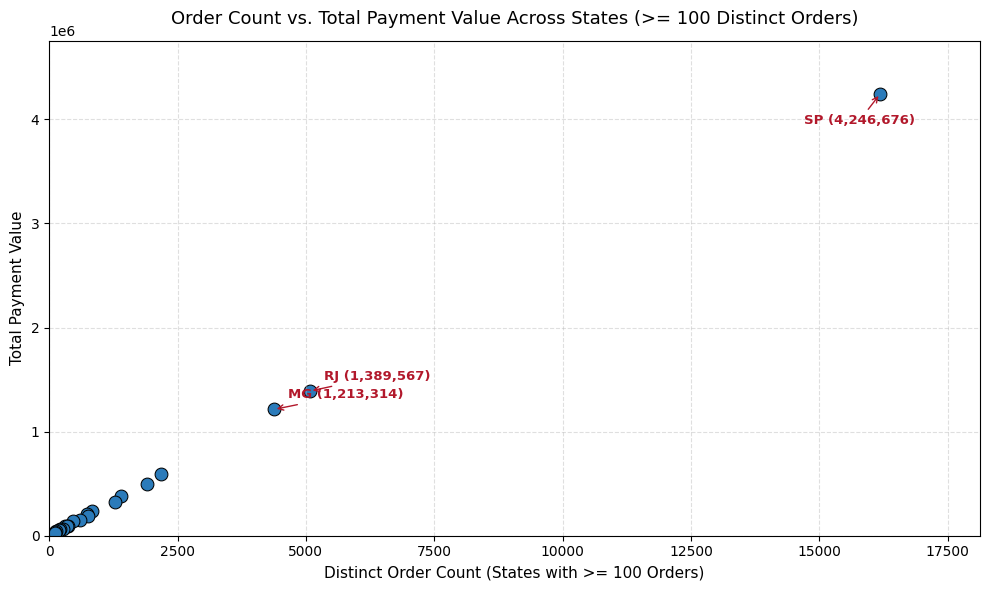

In [24]:
cust_orders = customers[["customer_id", "customer_state"]].merge(
    orders[["order_id", "customer_id"]],
    on="customer_id",
)

order_counts = (
    cust_orders.groupby("customer_state", as_index=False)["order_id"]
    .nunique()
    .rename(columns={"order_id": "order_count"})
)

pay_totals = (
    cust_orders[["customer_state", "order_id"]]
    .drop_duplicates()
    .merge(payments[["order_id", "payment_value"]], on="order_id")
    .groupby("customer_state", as_index=False)["payment_value"]
    .sum()
    .rename(columns={"payment_value": "total_payment_value"})
)

state_df = (
    order_counts.merge(pay_totals, on="customer_state", how="left")
    .fillna({"total_payment_value": 0.0})
    .query("order_count >= 100")
    .sort_values("total_payment_value", ascending=False)
    .reset_index(drop=True)
)

print(state_df.to_string(index=False))

top3_states = state_df.head(3)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=state_df,
    x="order_count",
    y="total_payment_value",
    s=85,
    color="#2b7bba",
    edgecolor="black",
)

x_max = state_df["order_count"].max()
y_max = state_df["total_payment_value"].max()

for idx, (_, row) in enumerate(top3_states.iterrows()):
    x_offset = -55 if idx == 0 else 10
    y_offset = -22 if idx == 0 else 8
    plt.annotate(
        f"{row['customer_state']} ({row['total_payment_value']:,.0f})",
        xy=(row["order_count"], row["total_payment_value"]),
        xytext=(x_offset, y_offset),
        textcoords="offset points",
        fontsize=9.5,
        fontweight="bold",
        color="#b2182b",
        arrowprops=dict(arrowstyle="->", color="#b2182b", lw=1),
    )

plt.xlabel("Distinct Order Count (States with >= 100 Orders)", fontsize=11)
plt.ylabel("Total Payment Value", fontsize=11)
plt.title(
    "Order Count vs. Total Payment Value Across States (>= 100 Distinct Orders)",
    fontsize=13,
    pad=12,
)
plt.xlim(0, x_max * 1.12)
plt.ylim(0, y_max * 1.12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q9

                 plotted_products  median     q25    q75        mean
category                                                            
toys                        12469   146.0  67.000  390.0  312.482318
bed_bath_table                429   127.0  62.000  319.0  285.985374
sports_leisure                361   165.0  83.000  349.0  308.644403
furniture_decor               351   189.0  89.125  518.0  421.273117
health_beauty                 325   151.0  68.000  390.0  307.269455
housewares                    319   135.0  62.625  364.5  270.755267


/tmp/ipykernel_550/4252538322.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


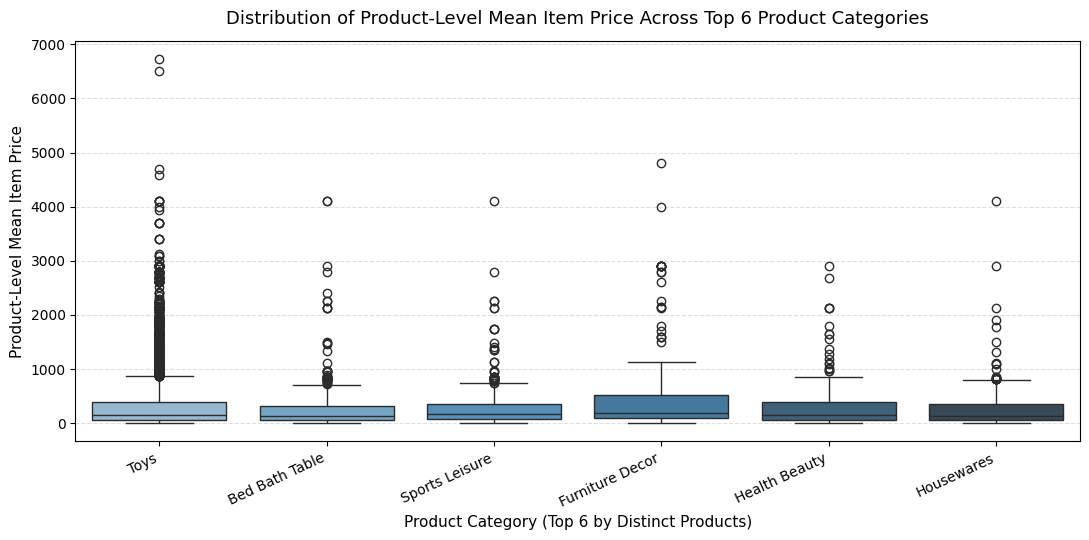

In [25]:
products["category"] = (
    products["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

top6_cats = (
    products.groupby("category")["product_id"]
    .nunique()
    .nlargest(6)
    .index.tolist()
)

prod_mean_prices = (
    order_items.groupby("product_id", as_index=False)["price"]
    .mean()
    .rename(columns={"price": "mean_item_price"})
    .merge(products[["product_id", "category"]], on="product_id", how="inner")
)

plot_df = prod_mean_prices[prod_mean_prices["category"].isin(top6_cats)].copy()
plot_df["display_category"] = plot_df["category"].str.replace("_", " ").str.title()
display_order = [c.replace("_", " ").title() for c in top6_cats]

summary_stats = (
    plot_df.groupby("category")["mean_item_price"]
    .agg(
        plotted_products="count",
        median="median",
        q25=lambda s: s.quantile(0.25),
        q75=lambda s: s.quantile(0.75),
        mean="mean",
    )
    .loc[top6_cats]
)
print(summary_stats)

plt.figure(figsize=(11, 5.5))
sns.boxplot(
    data=plot_df,
    x="display_category",
    y="mean_item_price",
    order=display_order,
    palette="Blues_d",
)

plt.xlabel("Product Category (Top 6 by Distinct Products)", fontsize=11)
plt.ylabel("Product-Level Mean Item Price", fontsize=11)
plt.title(
    "Distribution of Product-Level Mean Item Price Across Top 6 Product Categories",
    fontsize=13,
    pad=12,
)
plt.xticks(rotation=25, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q10

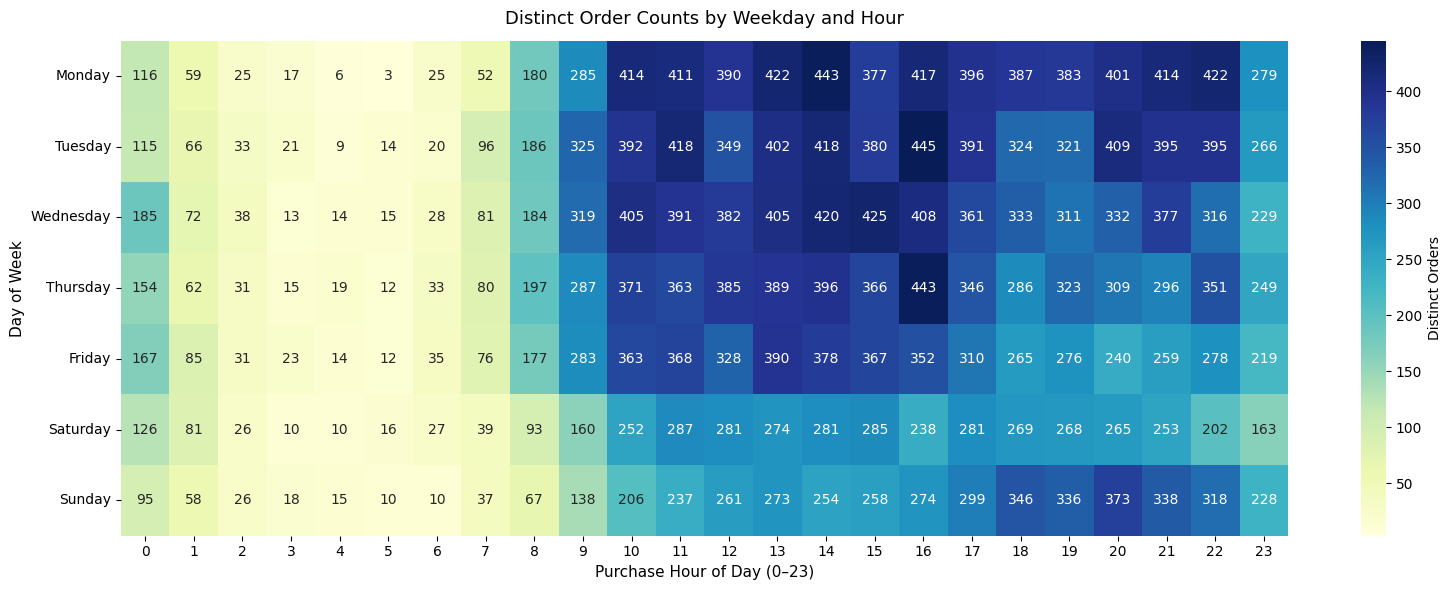

In [26]:
wh = orders[["order_id", "order_purchase_timestamp"]].dropna().copy()
wh["order_purchase_timestamp"] = pd.to_datetime(wh["order_purchase_timestamp"])
wh["hour"] = wh["order_purchase_timestamp"].dt.hour
wh["weekday"] = wh["order_purchase_timestamp"].dt.day_name()

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

heatmap_data = (
    wh.groupby(["weekday", "hour"])["order_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=weekday_order, columns=range(24), fill_value=0)
    .astype(int)
)

plt.figure(figsize=(16, 6))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    cbar_kws={"label": "Distinct Orders"},
)

plt.xlabel("Purchase Hour of Day (0–23)", fontsize=11)
plt.ylabel("Day of Week", fontsize=11)
plt.title("Distinct Order Counts by Weekday and Hour", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

Q11

                      category  mean_volume  mean_shipping_charges  mean_weight  item_count
         arts_and_craftmanship 34125.000000             107.000000  6850.000000           1
       fashion_underwear_beach  2168.000000              68.500000   287.500000           8
industry_commerce_and_business 41173.333333              65.388889  6893.055556          18
                          food  8760.687500              60.437500  1385.625000          16
                       Unknown 16801.339286              57.154762  2681.833333         168
                    food_drink  6367.857143              55.071429   754.357143          28
        tablets_printing_image  5187.789474              54.368421   291.947368          19
                  dvds_blu_ray  1632.800000              51.800000   250.000000           5
                           art  7357.500000              51.750000  4325.000000           4
           musical_instruments 19811.250000              50.442308  2755.730769 

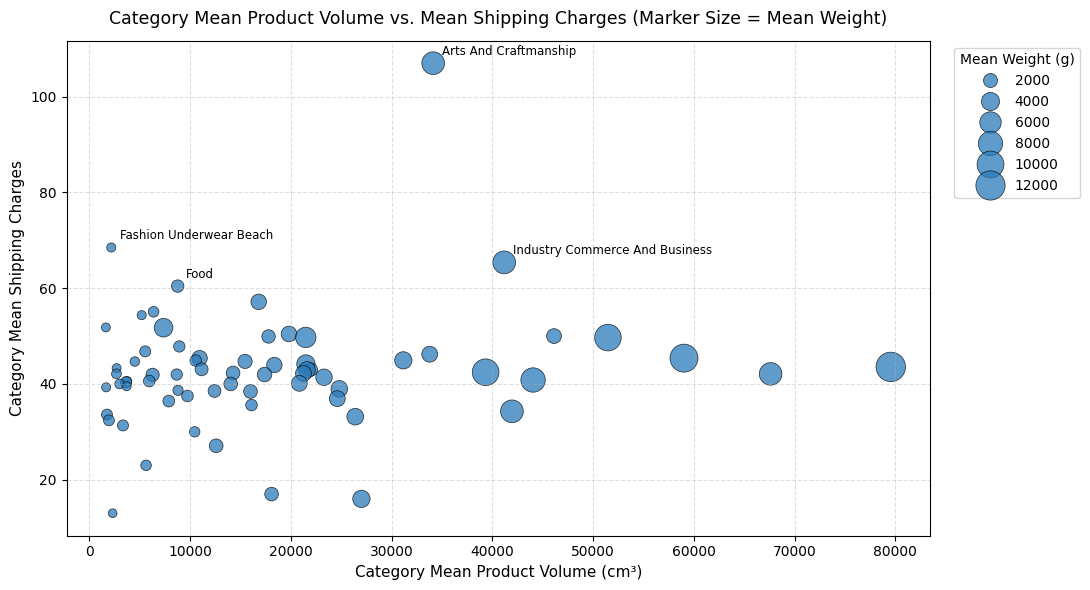

In [27]:
p_clean = products.copy()
p_clean["category"] = (
    p_clean["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

p_clean["product_volume_cm3"] = (
    p_clean["product_length_cm"]
    * p_clean["product_height_cm"]
    * p_clean["product_width_cm"]
)

valid_products = p_clean[
    (p_clean["product_weight_g"].notna())
    & (p_clean["product_weight_g"] > 0)
    & (p_clean["product_volume_cm3"].notna())
    & (p_clean["product_volume_cm3"] > 0)
][["product_id", "category", "product_volume_cm3", "product_weight_g"]]

df_merged = order_items[["product_id", "shipping_charges"]].merge(
    valid_products,
    on="product_id",
    how="inner",
)

cat_summary = (
    df_merged.groupby("category", as_index=False)
    .agg(
        mean_volume=("product_volume_cm3", "mean"),
        mean_shipping_charges=("shipping_charges", "mean"),
        mean_weight=("product_weight_g", "mean"),
        item_count=("product_id", "count"),
    )
    .sort_values("mean_shipping_charges", ascending=False)
)

print(cat_summary.head(10).to_string(index=False))

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=cat_summary,
    x="mean_volume",
    y="mean_shipping_charges",
    size="mean_weight",
    sizes=(40, 450),
    alpha=0.75,
    color="#2b7bba",
    edgecolor="black",
)

for _, row in cat_summary.nlargest(4, "mean_shipping_charges").iterrows():
    plt.annotate(
        row["category"].replace("_", " ").title(),
        xy=(row["mean_volume"], row["mean_shipping_charges"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8.5,
    )

plt.xlabel("Category Mean Product Volume (cm³)", fontsize=11)
plt.ylabel("Category Mean Shipping Charges", fontsize=11)
plt.title(
    "Category Mean Product Volume vs. Mean Shipping Charges (Marker Size = Mean Weight)",
    fontsize=12.5,
    pad=12,
)
plt.legend(title="Mean Weight (g)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q12

Available Observation Periods by Year:
 purchase_year  total_payment_value         first_order          last_order  active_months
          2018            5453883.0 2018-01-01 02:48:41 2018-09-03 09:06:57              9
          2017            4759972.0 2017-01-05 12:01:20 2017-12-31 21:10:02             12
          2016              33585.0 2016-10-03 16:56:50 2016-12-23 23:16:47              2

Payment-Type Totals for Top 2 Purchase Years:
purchase_year  2017 (Jan 2017–Dec 2017, 12 mos)  \
payment_type                                      
Credit Card                           3445211.0   
Wallet                                 937700.0   
Voucher                                341121.0   
Debit Card                              35940.0   

purchase_year  2018 (Jan 2018–Sep 2018, 9 mos)  
payment_type                                    
Credit Card                          4046347.0  
Wallet                               1019658.0  
Voucher                               293644.0 

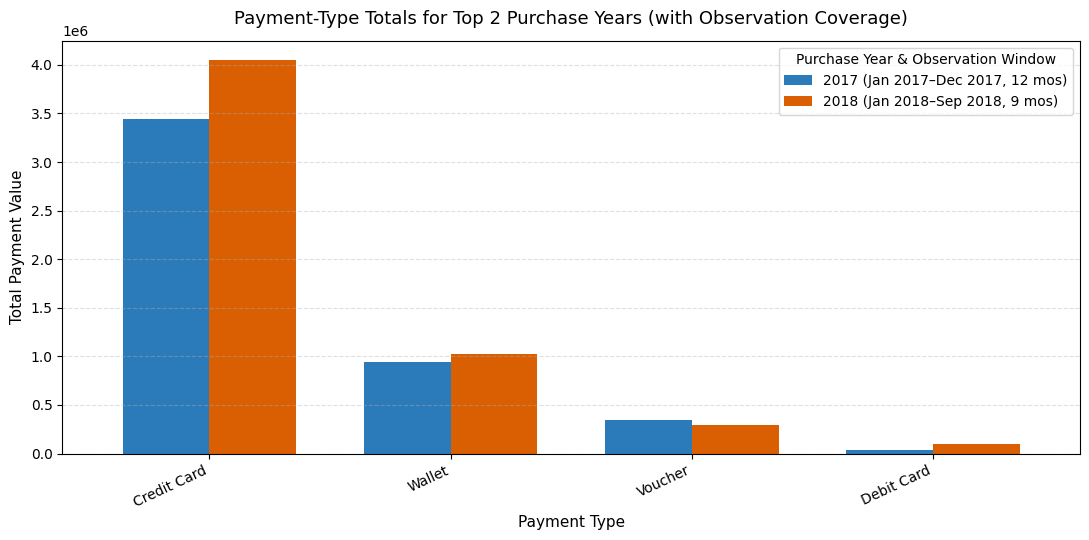

In [28]:
df_merged = payments[["order_id", "payment_type", "payment_value"]].merge(
    orders[["order_id", "order_purchase_timestamp"]].dropna(),
    on="order_id",
)
df_merged["order_purchase_timestamp"] = pd.to_datetime(
    df_merged["order_purchase_timestamp"]
)
df_merged["purchase_year"] = df_merged["order_purchase_timestamp"].dt.year
df_merged["payment_type"] = (
    df_merged["payment_type"]
    .fillna("Unknown")
    .str.replace("_", " ")
    .str.title()
)

year_coverage = (
    df_merged.groupby("purchase_year", as_index=False)
    .agg(
        total_payment_value=("payment_value", "sum"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max"),
        active_months=("order_purchase_timestamp", lambda s: s.dt.to_period("M").nunique()),
    )
    .sort_values("total_payment_value", ascending=False)
)

print("Available Observation Periods by Year:")
print(year_coverage.to_string(index=False))

top2_years = sorted(year_coverage.head(2)["purchase_year"].tolist())

top2_cov = year_coverage[year_coverage["purchase_year"].isin(top2_years)].sort_values(
    "purchase_year"
)
col_labels = {
    row["purchase_year"]: (
        f"{int(row['purchase_year'])} "
        f"({row['first_order'].strftime('%b %Y')}–{row['last_order'].strftime('%b %Y')}, "
        f"{int(row['active_months'])} mos)"
    )
    for _, row in top2_cov.iterrows()
}

piv_year_pay = (
    df_merged[df_merged["purchase_year"].isin(top2_years)]
    .groupby(["payment_type", "purchase_year"])["payment_value"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=top2_years)
    .rename(columns=col_labels)
)

piv_year_pay = piv_year_pay.loc[
    piv_year_pay.sum(axis=1).sort_values(ascending=False).index
]

print("\nPayment-Type Totals for Top 2 Purchase Years:")
print(piv_year_pay)

ax = piv_year_pay.plot(
    kind="bar",
    figsize=(11, 5.5),
    width=0.72,
    color=["#2b7bba", "#d95f02"],
)

ax.set_title(
    "Payment-Type Totals for Top 2 Purchase Years (with Observation Coverage)",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Payment Type", fontsize=11)
ax.set_ylabel("Total Payment Value", fontsize=11)
ax.legend(title="Purchase Year & Observation Window")

plt.xticks(rotation=25, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q13

Percentage Contribution by State:
payment_type    Credit Card  Wallet  Voucher  Debit Card
customer_state                                          
SP                    74.14   18.41     6.27        1.18
RJ                    74.46   16.54     7.10        1.89
MG                    73.98   18.83     5.75        1.44
RS                    66.56   28.19     4.78        0.46


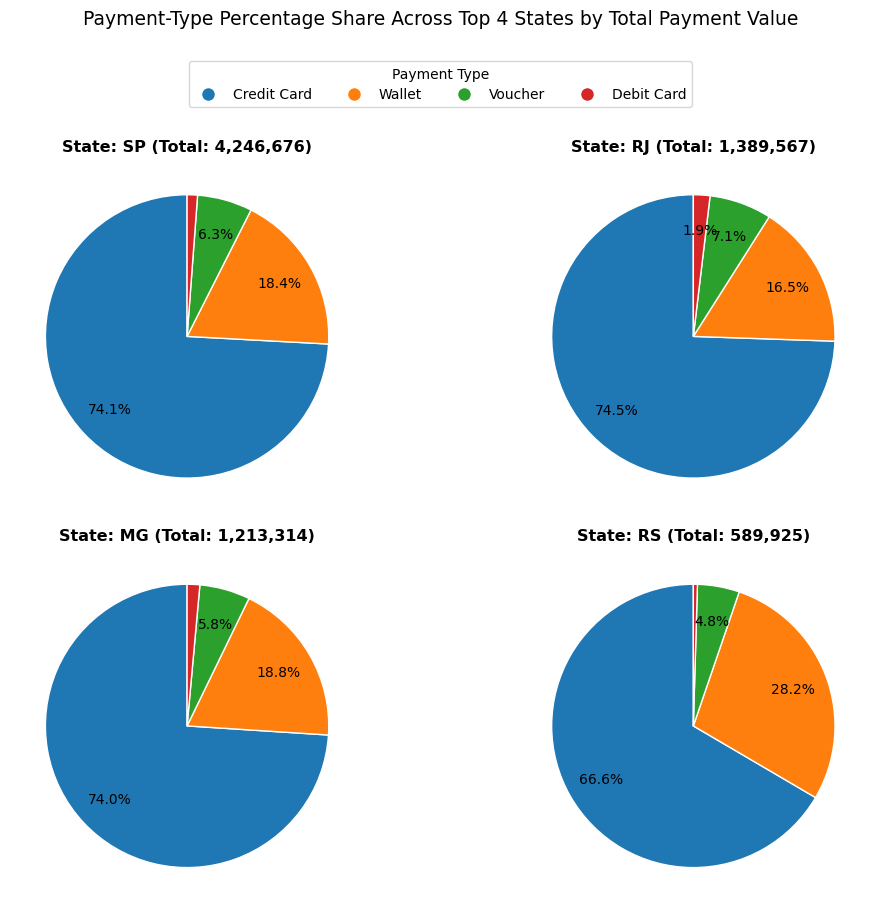

In [30]:
df_merged = (
    customers[["customer_id", "customer_state"]]
    .merge(orders[["order_id", "customer_id"]], on="customer_id")
    .merge(payments[["order_id", "payment_type", "payment_value"]], on="order_id")
)
df_merged["payment_type"] = (
    df_merged["payment_type"]
    .fillna("Unknown")
    .str.replace("_", " ")
    .str.title()
)

top4_pay_states = (
    df_merged.groupby("customer_state")["payment_value"]
    .sum()
    .nlargest(4)
    .index.tolist()
)

state_pay_totals = (
    df_merged[df_merged["customer_state"].isin(top4_pay_states)]
    .groupby(["customer_state", "payment_type"], as_index=False)["payment_value"]
    .sum()
)

all_payment_types = (
    state_pay_totals.groupby("payment_type")["payment_value"]
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

palette = dict(zip(all_payment_types, plt.cm.tab10.colors[: len(all_payment_types)]))

piv_pct = (
    state_pay_totals.pivot(
        index="customer_state",
        columns="payment_type",
        values="payment_value",
    )
    .reindex(index=top4_pay_states, columns=all_payment_types)
    .fillna(0.0)
)
piv_pct = piv_pct.div(piv_pct.sum(axis=1), axis=0) * 100.0
print("Percentage Contribution by State:")
print(piv_pct.round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, state in zip(axes.flat, top4_pay_states):
    sub = (
        state_pay_totals[state_pay_totals["customer_state"] == state]
        .set_index("payment_type")
        .reindex(all_payment_types)
        .fillna(0.0)
    )
    colors = [palette[pt] for pt in sub.index]
    wedges, texts, autotexts = ax.pie(
        sub["payment_value"],
        colors=colors,
        autopct=lambda pct: f"{pct:.1f}%" if pct >= 1.5 else "",
        startangle=90,
        pctdistance=0.75,
        wedgeprops=dict(edgecolor="white", linewidth=1),
    )
    ax.set_title(
        f"State: {state} (Total: {sub['payment_value'].sum():,.0f})",
        fontsize=11.5,
        fontweight="bold",
    )

legend_handles = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=palette[pt], markersize=10, label=pt)
    for pt in all_payment_types
]
fig.legend(
    handles=legend_handles,
    title="Payment Type",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=len(all_payment_types),
    frameon=True,
)

fig.suptitle(
    "Payment-Type Percentage Share Across Top 4 States by Total Payment Value",
    fontsize=13.5,
    y=1.01,
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

Q14

purchase_month  median_approval_delay_hours  valid_order_count
       2016-10                    13.250833                113
       2016-12                     0.247222                  1
       2017-01                     0.434444                332
       2017-02                     0.228056                657
       2017-03                     0.000000               1058
       2017-04                     0.246250                908
       2017-05                     0.239444               1461
       2017-06                     0.261667               1238
       2017-07                     0.255972               1602
       2017-08                     0.319722               1753
       2017-09                     0.273611               1711
       2017-10                     0.313333               1890
       2017-11                     0.455833               2926
       2017-12                     0.368889               2115
       2018-01                     0.308333            

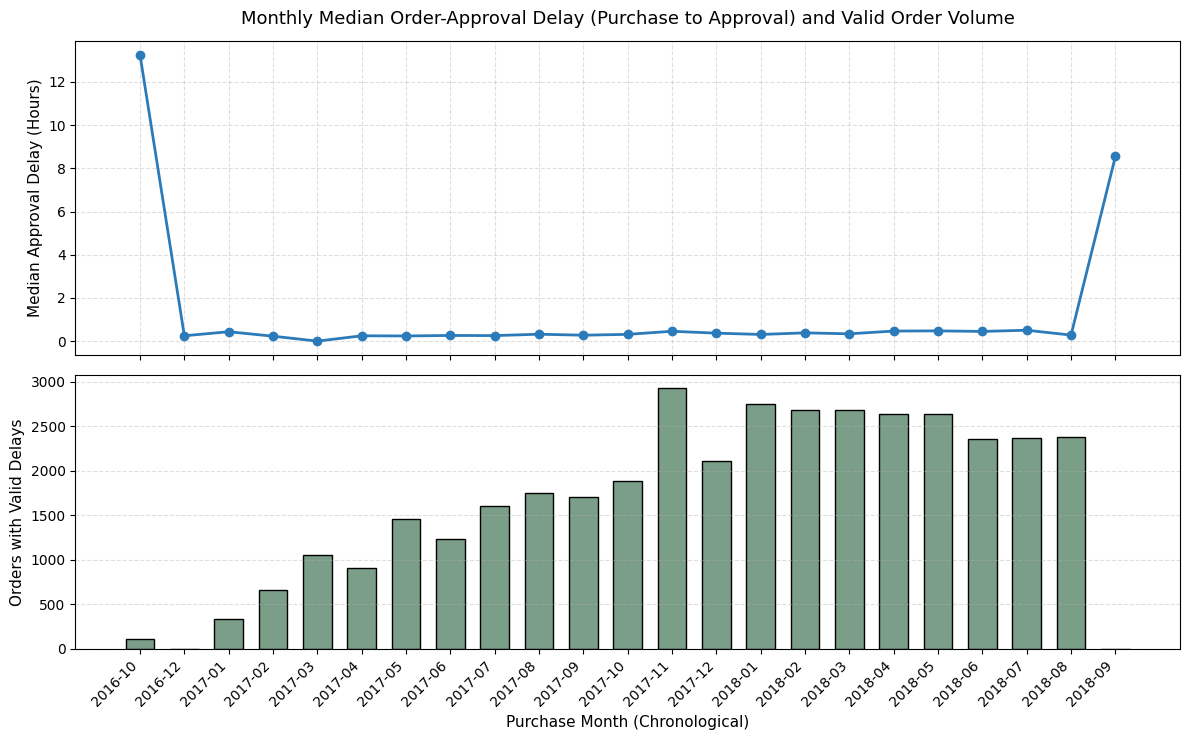

In [31]:
approval_df = orders[
    ["order_id", "order_purchase_timestamp", "order_approved_at"]
].dropna().copy()

approval_df["order_purchase_timestamp"] = pd.to_datetime(
    approval_df["order_purchase_timestamp"]
)
approval_df["order_approved_at"] = pd.to_datetime(
    approval_df["order_approved_at"]
)

approval_df["approval_delay_hours"] = (
    approval_df["order_approved_at"] - approval_df["order_purchase_timestamp"]
).dt.total_seconds() / 3600.0

valid_approval = approval_df[approval_df["approval_delay_hours"] >= 0].copy()
valid_approval["purchase_month"] = (
    valid_approval["order_purchase_timestamp"].dt.to_period("M")
)

monthly_approval = (
    valid_approval.groupby("purchase_month", as_index=False)
    .agg(
        median_approval_delay_hours=("approval_delay_hours", "median"),
        valid_order_count=("order_id", "nunique"),
    )
    .sort_values("purchase_month")
)

print(monthly_approval.to_string(index=False))

x_months = monthly_approval["purchase_month"].astype(str)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]}
)

ax1.plot(
    x_months,
    monthly_approval["median_approval_delay_hours"],
    marker="o",
    linewidth=2,
    markersize=6,
    color="#2b7bba",
)
ax1.set_ylabel("Median Approval Delay (Hours)", fontsize=11)
ax1.set_title(
    "Monthly Median Order-Approval Delay (Purchase to Approval) and Valid Order Volume",
    fontsize=13,
    pad=12,
)
ax1.grid(True, linestyle="--", alpha=0.4)

ax2.bar(
    x_months,
    monthly_approval["valid_order_count"],
    color="#7b9e89",
    edgecolor="black",
    width=0.65,
)
ax2.set_ylabel("Orders with Valid Delays", fontsize=11)
ax2.set_xlabel("Purchase Month (Chronological)", fontsize=11)
ax2.grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Q15

               city_state  distinct_orders  total_item_price
            Sao Paulo, SP             6160         2002615.0
       Rio De Janeiro, RJ             2730          918209.0
       Belo Horizonte, MG             1086          379168.0
             Brasilia, DF              837          286364.0
         Porto Alegre, RS              577          231138.0
             Curitiba, PR              562          201513.0
            Guarulhos, SP              483          197316.0
             Campinas, SP              555          194074.0
             Salvador, BA              489          164152.0
Sao Bernardo Do Campo, SP              359          129758.0


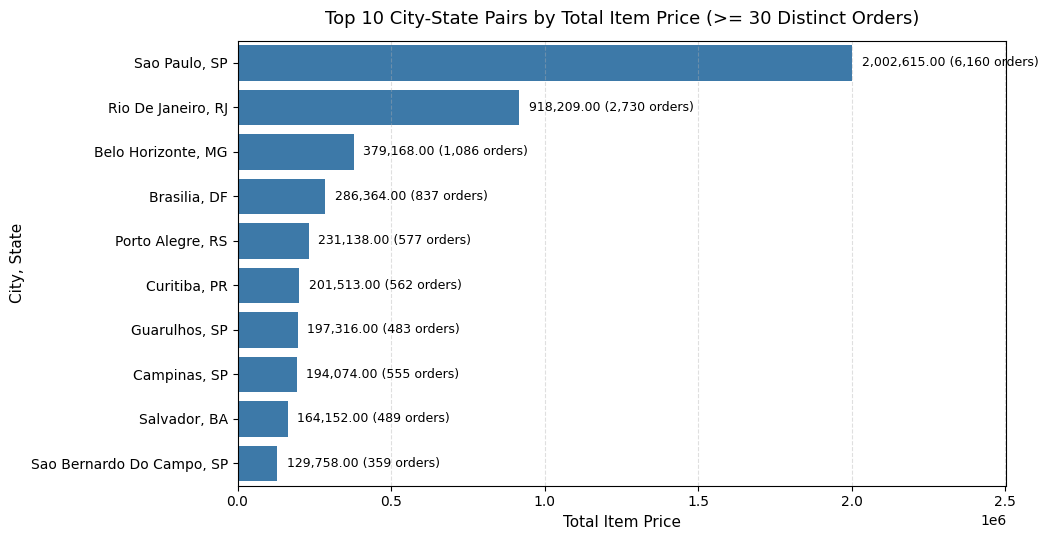

In [32]:
cust_clean = customers[["customer_id", "customer_city", "customer_state"]].copy()
cust_clean["customer_city"] = (
    cust_clean["customer_city"].fillna("Unknown").astype(str).str.strip()
)
cust_clean["customer_state"] = (
    cust_clean["customer_state"].fillna("Unknown").astype(str).str.strip()
)

df_merged = (
    order_items[["order_id", "price"]]
    .merge(orders[["order_id", "customer_id"]], on="order_id")
    .merge(cust_clean, on="customer_id")
)

city_state_summary = (
    df_merged.groupby(["customer_city", "customer_state"], as_index=False)
    .agg(
        distinct_orders=("order_id", "nunique"),
        total_item_price=("price", "sum"),
    )
    .query("distinct_orders >= 30")
    .sort_values("total_item_price", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

city_state_summary["city_state"] = (
    city_state_summary["customer_city"].str.title()
    + ", "
    + city_state_summary["customer_state"]
)

print(
    city_state_summary[
        ["city_state", "distinct_orders", "total_item_price"]
    ].to_string(index=False)
)

plt.figure(figsize=(10.5, 5.5))
ax = sns.barplot(
    data=city_state_summary,
    x="total_item_price",
    y="city_state",
    color="#2b7bba",
)

max_val = city_state_summary["total_item_price"].max()
ax.set_xlim(0, max_val * 1.25)

for bar, (_, row) in zip(ax.patches, city_state_summary.iterrows()):
    ax.text(
        bar.get_width() + max_val * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{row['total_item_price']:,.2f} ({int(row['distinct_orders']):,} orders)",
        va="center",
        fontsize=9,
    )

ax.set_xlabel("Total Item Price", fontsize=11)
ax.set_ylabel("City, State", fontsize=11)
ax.set_title(
    "Top 10 City-State Pairs by Total Item Price (>= 30 Distinct Orders)",
    fontsize=13,
    pad=12,
)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q16

installment_band         1       2-3       4-6        7+
purchase_month                                          
2016-10             5802.0    5379.0    6357.0    7056.0
2016-12              352.0       0.0       0.0       0.0
2017-01            19817.0   12899.0   14407.0   15138.0
2017-02            45835.0   29344.0   21168.0   28208.0
2017-03            67117.0   44623.0   41703.0   44323.0
2017-04            61596.0   47914.0   39675.0   31085.0
2017-05            63658.0   74317.0   71702.0   77422.0
2017-06            53410.0   76149.0   56275.0   42940.0
2017-07            70598.0   99539.0   77731.0   60507.0
2017-08            85418.0   92746.0   78755.0   96968.0
2017-09           105532.0   80339.0   75761.0   75610.0
2017-10           100949.0  104358.0   79833.0   67113.0
2017-11           185947.0  178815.0  117626.0  133644.0
2017-12           144517.0  101034.0   84774.0   66372.0
2018-01           211050.0  138785.0  117246.0   67771.0
2018-02           193831.0  165

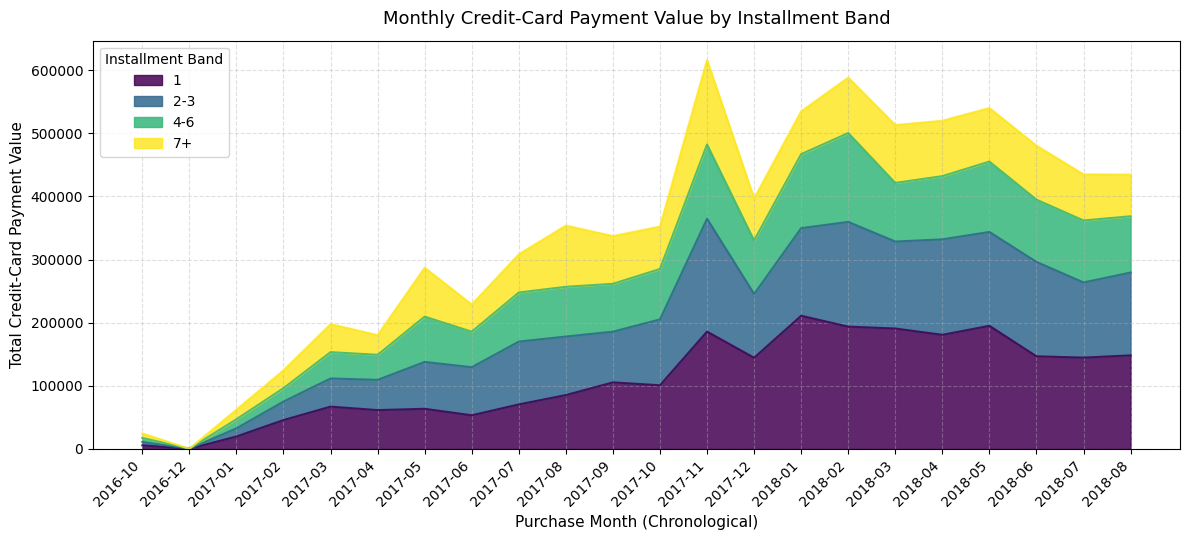

In [33]:
cc_payments = payments[
    (payments["payment_type"] == "credit_card")
    & (payments["payment_installments"].notna())
    & (payments["payment_installments"] > 0)
][["order_id", "payment_installments", "payment_value"]].copy()

cc_payments["installment_band"] = pd.cut(
    cc_payments["payment_installments"],
    bins=[0, 1, 3, 6, float("inf")],
    labels=["1", "2-3", "4-6", "7+"],
)

df_merged = cc_payments.merge(
    orders[["order_id", "order_purchase_timestamp"]].dropna(),
    on="order_id",
)
df_merged["order_purchase_timestamp"] = pd.to_datetime(
    df_merged["order_purchase_timestamp"]
)
df_merged["purchase_month"] = df_merged["order_purchase_timestamp"].dt.to_period("M")

band_order = ["1", "2-3", "4-6", "7+"]

monthly_cc = (
    df_merged.groupby(["purchase_month", "installment_band"], observed=False)[
        "payment_value"
    ]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=band_order, fill_value=0)
    .sort_index()
)

monthly_cc.index = monthly_cc.index.astype(str)

print(monthly_cc)

ax = monthly_cc.plot(
    kind="area",
    stacked=True,
    figsize=(12, 5.5),
    alpha=0.85,
    colormap="viridis",
)

ax.set_title(
    "Monthly Credit-Card Payment Value by Installment Band",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Purchase Month (Chronological)", fontsize=11)
ax.set_ylabel("Total Credit-Card Payment Value", fontsize=11)
ax.legend(title="Installment Band", loc="upper left")

plt.xticks(
    ticks=range(len(monthly_cc.index)),
    labels=monthly_cc.index,
    rotation=45,
    ha="right",
)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q17

                             category  total_shipping_charges  total_item_price  shipping_to_price_pct
                arts_and_craftmanship                   107.0              37.0             289.189189
                                music                    40.0              23.0             173.913043
           agro_industry_and_commerce                   800.0            2198.0              36.396724
       industry_commerce_and_business                  1177.0            3865.0              30.452781
                          electronics                 10063.0           40006.0              25.153727
small_appliances_home_oven_and_coffee                   300.0            1222.0              24.549918
                    home_appliances_2                  1540.0            6472.0              23.794808
    furniture_mattress_and_upholstery                    17.0              77.0              22.077922
                                  art                   207.0            

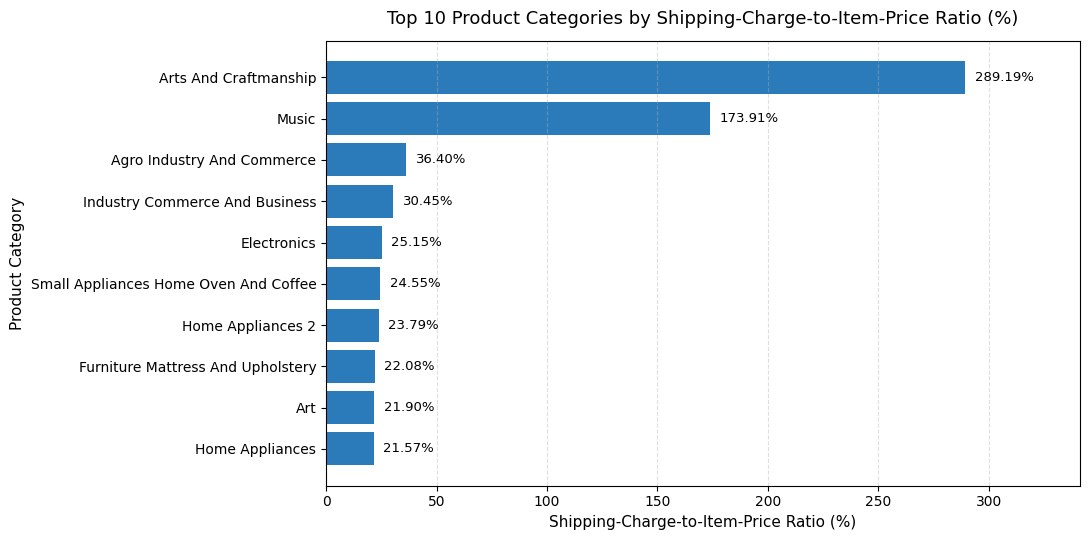

In [34]:
products["category"] = (
    products["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

df_merged = order_items[["product_id", "price", "shipping_charges"]].merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left",
)
df_merged["category"] = df_merged["category"].fillna("Unknown")

cat_ratios = (
    df_merged.groupby("category", as_index=False)
    .agg(
        total_item_price=("price", "sum"),
        total_shipping_charges=("shipping_charges", "sum"),
    )
    .query("total_item_price > 0")
)

cat_ratios["shipping_to_price_pct"] = (
    cat_ratios["total_shipping_charges"] / cat_ratios["total_item_price"]
) * 100.0

top10_ratios = (
    cat_ratios.sort_values("shipping_to_price_pct", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
top10_ratios["display_category"] = (
    top10_ratios["category"].str.replace("_", " ").str.title()
)

print(
    top10_ratios[
        [
            "category",
            "total_shipping_charges",
            "total_item_price",
            "shipping_to_price_pct",
        ]
    ].to_string(index=False)
)

plot_df = top10_ratios.iloc[::-1]

plt.figure(figsize=(11, 5.5))
bars = plt.barh(
    plot_df["display_category"],
    plot_df["shipping_to_price_pct"],
    color="#2b7bba",
)

max_val = plot_df["shipping_to_price_pct"].max()
plt.xlim(0, max_val * 1.18)

for bar, pct in zip(bars, plot_df["shipping_to_price_pct"]):
    plt.text(
        bar.get_width() + max_val * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.2f}%",
        va="center",
        fontsize=9.5,
    )

plt.xlabel("Shipping-Charge-to-Item-Price Ratio (%)", fontsize=11)
plt.ylabel("Product Category", fontsize=11)
plt.title(
    "Top 10 Product Categories by Shipping-Charge-to-Item-Price Ratio (%)",
    fontsize=13,
    pad=12,
)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q18

Mean Payment Value (Groups with >= 20 Distinct Orders):
payment_type  Voucher  Credit Card  Wallet  Debit Card
weekday                                               
Monday         268.58       264.64  265.10      387.38
Tuesday        308.18       268.61  272.91      227.56
Wednesday      308.86       259.40  240.99      251.88
Thursday       309.48       274.97  277.59      269.23
Friday         286.56       269.08  257.96      188.39
Saturday       372.13       266.65  262.70      220.85
Sunday         290.37       257.68  276.33      272.10


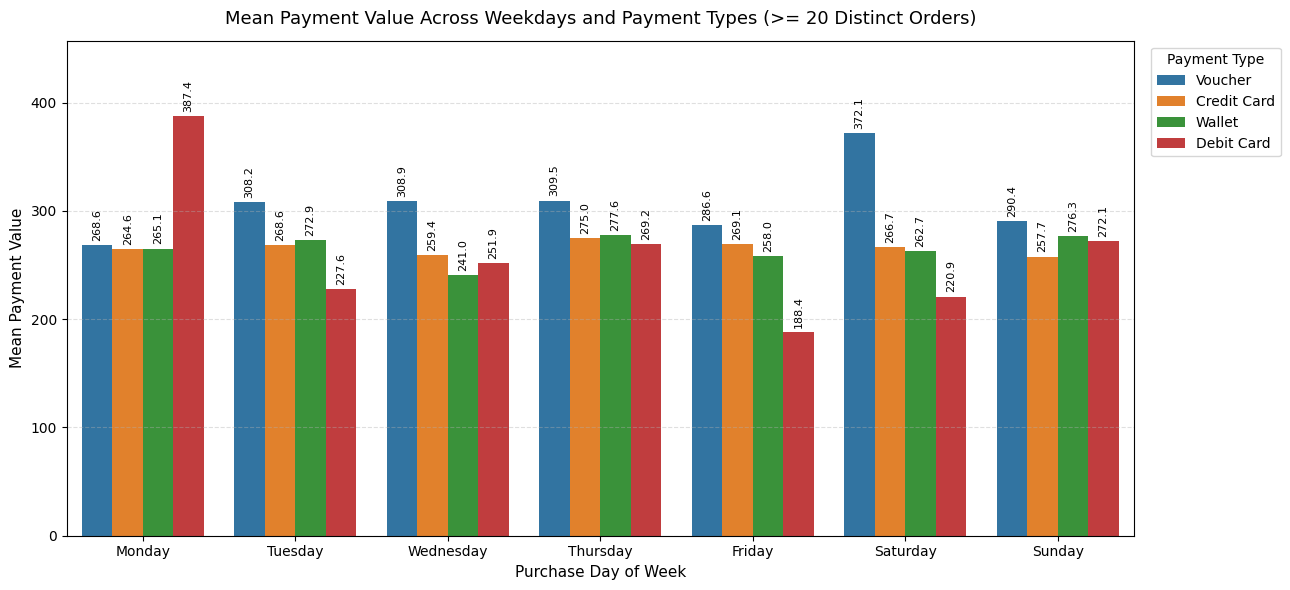

In [35]:
df_merged = payments[["order_id", "payment_type", "payment_value"]].merge(
    orders[["order_id", "order_purchase_timestamp"]].dropna(),
    on="order_id",
)

df_merged["order_purchase_timestamp"] = pd.to_datetime(
    df_merged["order_purchase_timestamp"]
)
df_merged["weekday"] = df_merged["order_purchase_timestamp"].dt.day_name()
df_merged["payment_type"] = (
    df_merged["payment_type"]
    .fillna("Unknown")
    .str.replace("_", " ")
    .str.title()
)

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

group_summary = (
    df_merged.groupby(["weekday", "payment_type"], as_index=False)
    .agg(
        distinct_orders=("order_id", "nunique"),
        mean_payment_value=("payment_value", "mean"),
    )
    .query("distinct_orders >= 20")
)

payment_order = (
    group_summary.groupby("payment_type")["mean_payment_value"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

piv_table = (
    group_summary.pivot(
        index="weekday",
        columns="payment_type",
        values="mean_payment_value",
    )
    .reindex(index=weekday_order, columns=payment_order)
)

print("Mean Payment Value (Groups with >= 20 Distinct Orders):")
print(piv_table.round(2))

plt.figure(figsize=(13, 6))
ax = sns.barplot(
    data=group_summary,
    x="weekday",
    y="mean_payment_value",
    hue="payment_type",
    order=weekday_order,
    hue_order=payment_order,
    errorbar=None,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8, rotation=90)

max_val = group_summary["mean_payment_value"].max()
ax.set_ylim(0, max_val * 1.18)

ax.set_xlabel("Purchase Day of Week", fontsize=11)
ax.set_ylabel("Mean Payment Value", fontsize=11)
ax.set_title(
    "Mean Payment Value Across Weekdays and Payment Types (>= 20 Distinct Orders)",
    fontsize=13,
    pad=12,
)
ax.legend(title="Payment Type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Q19

 purchase_year  distinct_orders  total_item_price         first_order          last_order                      coverage_status
          2016              114           36712.0 2016-10-03 16:56:50 2016-12-23 23:16:47    Incomplete (Oct 03–Dec 23, 2 mos)
          2017            17658         6209478.0 2017-01-05 12:01:20 2017-12-31 21:10:02 Complete (Jan 2017–Dec 2017, 12 mos)
          2018            20507         6865642.0 2018-01-01 02:48:41 2018-09-03 09:06:57    Incomplete (Jan 01–Sep 03, 9 mos)


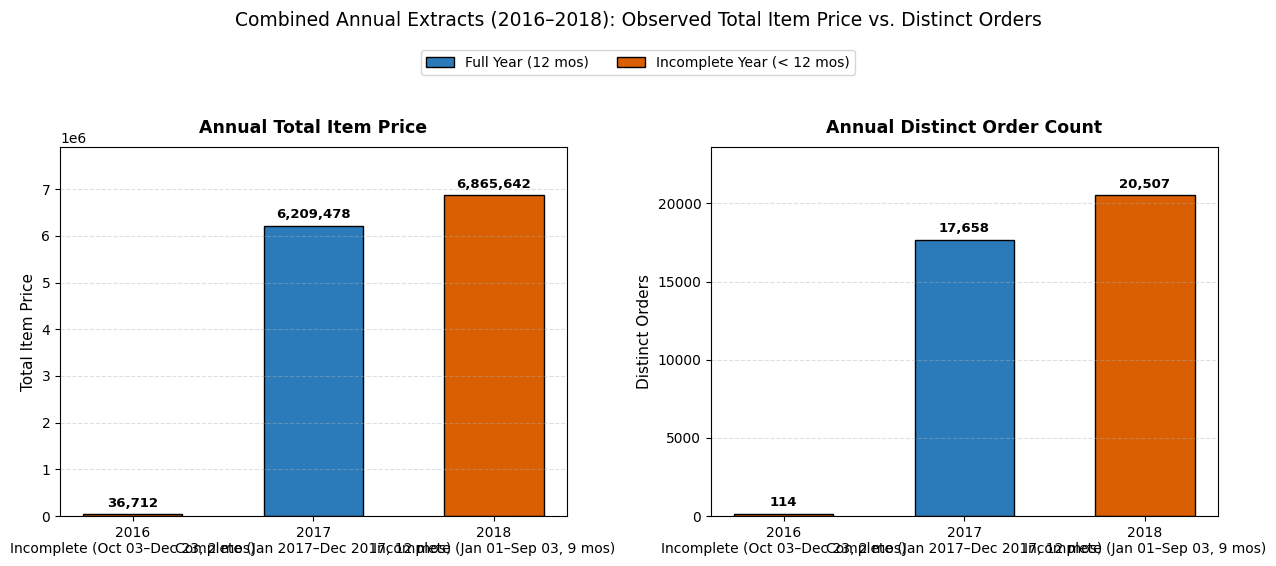

In [36]:
# Separate orders into annual extracts (2016, 2017, 2018)
orders_ts = orders.dropna(subset=["order_purchase_timestamp"]).copy()
orders_ts["order_purchase_timestamp"] = pd.to_datetime(
    orders_ts["order_purchase_timestamp"]
)
orders_ts["purchase_year"] = orders_ts["order_purchase_timestamp"].dt.year

extract_2016 = orders_ts[orders_ts["purchase_year"] == 2016].copy()
extract_2017 = orders_ts[orders_ts["purchase_year"] == 2017].copy()
extract_2018 = orders_ts[orders_ts["purchase_year"] == 2018].copy()

# Combine the three annual extracts without losing or duplicating order IDs
combined_orders = (
    pd.concat([extract_2016, extract_2017, extract_2018], ignore_index=True)
    .drop_duplicates(subset=["order_id"], keep="first")
)

# Verify integrity against source orders for 2016–2018
expected_ids = orders_ts[orders_ts["purchase_year"].isin([2016, 2017, 2018])][
    "order_id"
].nunique()
assert len(combined_orders) == expected_ids, "Order count mismatch after combining!"

# Aggregate item price at the order level first to prevent row duplication
order_item_totals = (
    order_items.groupby("order_id", as_index=False)["price"]
    .sum()
    .rename(columns={"price": "order_item_total"})
)

orders_with_items = combined_orders.merge(
    order_item_totals,
    on="order_id",
    how="left",
).fillna({"order_item_total": 0.0})

# Summarize annual metrics and observation windows
annual_summary = (
    orders_with_items.groupby("purchase_year", as_index=False)
    .agg(
        distinct_orders=("order_id", "nunique"),
        total_item_price=("order_item_price", "sum")
        if "order_item_price" in orders_with_items
        else ("order_item_total", "sum"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max"),
        active_months=(
            "order_purchase_timestamp",
            lambda s: s.dt.to_period("M").nunique(),
        ),
    )
    .sort_values("purchase_year")
    .reset_index(drop=True)
)

# Flag incomplete calendar year coverage
annual_summary["coverage_status"] = annual_summary.apply(
    lambda r: (
        f"Complete ({r['first_order'].strftime('%b %Y')}–{r['last_order'].strftime('%b %Y')}, {int(r['active_months'])} mos)"
        if r["active_months"] == 12
        else f"Incomplete ({r['first_order'].strftime('%b %d')}–{r['last_order'].strftime('%b %d')}, {int(r['active_months'])} mos)"
    ),
    axis=1,
)

annual_summary["x_label"] = (
    annual_summary["purchase_year"].astype(str)
    + "\n"
    + annual_summary["coverage_status"]
)

print(
    annual_summary[
        [
            "purchase_year",
            "distinct_orders",
            "total_item_price",
            "first_order",
            "last_order",
            "coverage_status",
        ]
    ].to_string(index=False)
)

# Plot two Matplotlib bar-chart subplots
bar_colors = [
    "#d95f02" if m < 12 else "#2b7bba" for m in annual_summary["active_months"]
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# Subplot 1: Total Item Price
bars1 = ax1.bar(
    annual_summary["x_label"],
    annual_summary["total_item_price"],
    color=bar_colors,
    edgecolor="black",
    width=0.55,
)
ax1.set_title("Annual Total Item Price", fontsize=12.5, fontweight="bold", pad=10)
ax1.set_ylabel("Total Item Price", fontsize=11)
ax1.set_ylim(0, annual_summary["total_item_price"].max() * 1.15)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
for bar in bars1:
    h = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        h + annual_summary["total_item_price"].max() * 0.015,
        f"{h:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )

# Subplot 2: Distinct Order Count
bars2 = ax2.bar(
    annual_summary["x_label"],
    annual_summary["distinct_orders"],
    color=bar_colors,
    edgecolor="black",
    width=0.55,
)
ax2.set_title("Annual Distinct Order Count", fontsize=12.5, fontweight="bold", pad=10)
ax2.set_ylabel("Distinct Orders", fontsize=11)
ax2.set_ylim(0, annual_summary["distinct_orders"].max() * 1.15)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
for bar in bars2:
    h = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        h + annual_summary["distinct_orders"].max() * 0.015,
        f"{int(h):,}",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor="#2b7bba", edgecolor="black", label="Full Year (12 mos)"),
    plt.Rectangle((0, 0), 1, 1, facecolor="#d95f02", edgecolor="black", label="Incomplete Year (< 12 mos)"),
]
fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=2,
    frameon=True,
)

fig.suptitle(
    "Combined Annual Extracts (2016–2018): Observed Total Item Price vs. Distinct Orders",
    fontsize=13.5,
    y=1.02,
)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

Q20

Separate payment extracts: {'Credit Card': 28265, 'Wallet': 7432, 'Voucher': 2090, 'Debit Card': 492}

Reconstructed Payment Summary:
              total_payment_value  mean_installments  payment_records
payment_type                                                         
Credit Card             7516504.0           3.684345            28265
Wallet                  1963594.0           1.000000             7432
Voucher                  637168.0           1.000000             2090
Debit Card               130174.0           1.000000              492


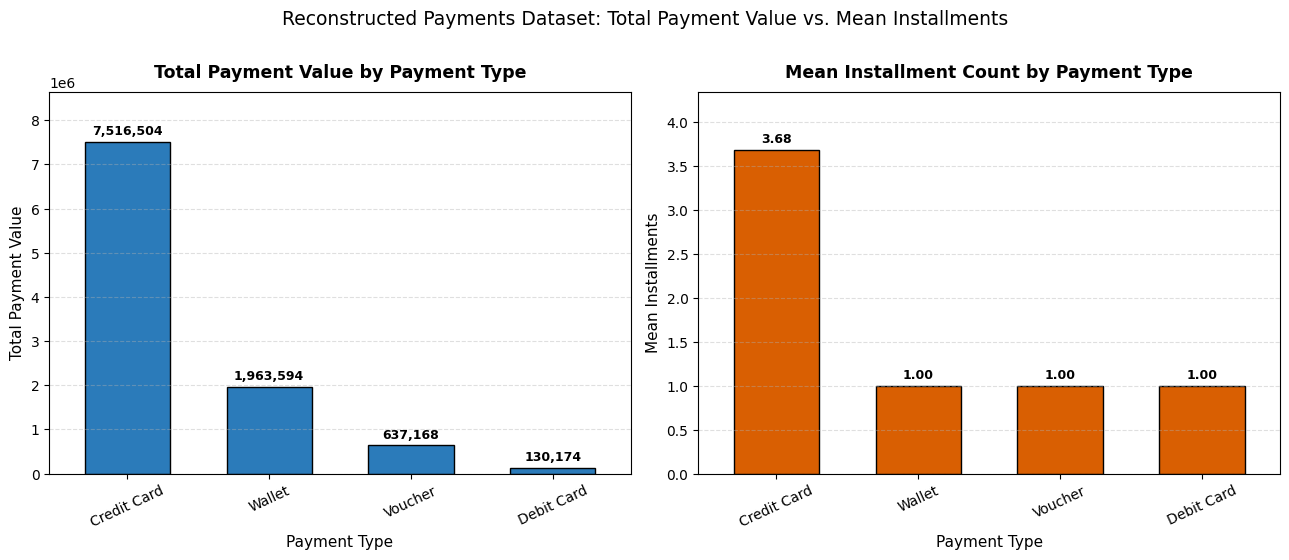

In [38]:
payments_clean = payments.copy()
payments_clean["payment_type"] = (
    payments_clean["payment_type"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .str.replace("_", " ")
    .str.title()
)

payment_extracts = {
    ptype: group.copy()
    for ptype, group in payments_clean.groupby("payment_type", sort=False)
}

print("Separate payment extracts:", {k: len(v) for k, v in payment_extracts.items()})

reconstructed_payments = pd.concat(payment_extracts.values(), ignore_index=True)

assert len(reconstructed_payments) == len(payments_clean), "Row count mismatch!"

pay_summary = (
    reconstructed_payments.groupby("payment_type", as_index=False)
    .agg(
        total_payment_value=("payment_value", "sum"),
        mean_installments=("payment_installments", "mean"),
        payment_records=("payment_value", "count"),
    )
    .sort_values("total_payment_value", ascending=False)
    .set_index("payment_type")
)

category_order = pay_summary.index.tolist()
pay_summary = pay_summary.reindex(category_order)

print("\nReconstructed Payment Summary:")
print(pay_summary)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

pay_summary["total_payment_value"].plot(
    kind="bar",
    ax=ax1,
    color="#2b7bba",
    edgecolor="black",
    width=0.6,
)
ax1.set_title("Total Payment Value by Payment Type", fontsize=12.5, fontweight="bold", pad=10)
ax1.set_xlabel("Payment Type", fontsize=11)
ax1.set_ylabel("Total Payment Value", fontsize=11)
ax1.set_ylim(0, pay_summary["total_payment_value"].max() * 1.15)
ax1.tick_params(axis="x", rotation=25)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax1.containers:
    ax1.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9, fontweight="bold")

pay_summary["mean_installments"].plot(
    kind="bar",
    ax=ax2,
    color="#d95f02",
    edgecolor="black",
    width=0.6,
)
ax2.set_title("Mean Installment Count by Payment Type", fontsize=12.5, fontweight="bold", pad=10)
ax2.set_xlabel("Payment Type", fontsize=11)
ax2.set_ylabel("Mean Installments", fontsize=11)
ax2.set_ylim(0, pay_summary["mean_installments"].max() * 1.18)
ax2.tick_params(axis="x", rotation=25)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax2.containers:
    ax2.bar_label(container, fmt="%.2f", padding=3, fontsize=9, fontweight="bold")

fig.suptitle(
    "Reconstructed Payments Dataset: Total Payment Value vs. Mean Installments",
    fontsize=13.5,
    y=1.01,
)
plt.tight_layout()
plt.show()